In [20]:
"""
Unit 5: Evolving Your IPD Agent with Genetic Algorithms
========================================================

In Unit 4, you hand-coded agent strategies like Tit-for-Tat.
In Unit 5, you'll use evolution to DISCOVER strategies automatically.

By the end, you'll have an evolved agent saved as a JSON file for the tournament!
"""

# ============================================================================
# SETUP: Import everything from previous units
# ============================================================================

import random
import numpy as np
import json
import matplotlib.pyplot as plt
from agents import Agent, INVEST, UNDERCUT
from game_engine import Game, Tournament

# Import all hand-coded agents from Unit 4
from agents import (
    AlwaysInvestAgent, AlwaysUndercutAgent, TitForTatAgent,
    GrimTriggerAgent, PavlovAgent, TitForTwoTatsAgent,
    GenerousTitForTatAgent, AdaptiveAgent, RandomAgent,
    SuspiciousTitForTatAgent, GradualAgent, HardMajorityAgent,
    SoftMajorityAgent, ProberAgent
)

print("✅ Imports complete!")

✅ Imports complete!


In [21]:

# ============================================================================
# PART 1: THE EVOLVABLE AGENT (PROVIDED - Read but don't modify)
# ============================================================================

class EvolvableAgent(Agent):
    """
    An agent whose strategy is controlled by 6 genes (numbers from 0 to 1).
    
    Think of genes as "strategy dials" you can tune:
    
    Gene[0] - Initial Cooperation (0=hostile start, 1=friendly start)
    Gene[1] - Cooperation Response (if opponent cooperates, how likely to cooperate back?)
    Gene[2] - Defection Response (if opponent defects, how likely to defect back?)
    Gene[3] - Forgiveness (after retaliation, chance to forgive)
    Gene[4] - Memory Length (0=last 1 round, 1=last 10 rounds)
    Gene[5] - Retaliation Threshold (what % of defections triggers retaliation)
    """
    
    def __init__(self, genes=None, name="Evolved Agent"):
        if genes is None:
            # Create random genes if none provided
            genes = [random.random() for _ in range(6)]
        
        self.genes = genes
        super().__init__(name, f"Genes: [{', '.join([f'{g:.2f}' for g in genes])}]")
    
    def choose_action(self) -> bool:
        """Decision logic based on genes - SIMPLIFIED FOR LEARNING"""
        
        # First 3 rounds: use initial cooperation gene
        if self.round_num < 3:
            return random.random() < self.genes[0]
        
        # Calculate memory window (gene[4])
        memory_length = max(1, int(self.genes[4] * 10) + 1)
        recent_history = self.history[-memory_length:]
        
        # Calculate opponent's recent COOPERATION rate (not defection!)
        cooperation_rate = sum(recent_history) / len(recent_history)
        
        # If opponent is mostly cooperating, reciprocate
        if cooperation_rate >= 0.5:
            return random.random() < self.genes[1]  # gene[1] = cooperate response
        
        # If opponent is mostly defecting, retaliate or forgive
        else:
            # Retaliate with probability gene[2]
            if random.random() < self.genes[2]:
                return UNDERCUT
            # Or forgive with probability gene[3]
            elif random.random() < self.genes[3]:
                return INVEST
            else:
                return UNDERCUT


In [22]:

# ============================================================================
# PART 2: DEFINE THE OPPONENT ECOSYSTEM
# ============================================================================

# ============================================================================
# EXPANDED OPPONENT POOL
# ============================================================================

# Full pool of all possible opponents
full_opponent_pool = [
    # Cooperative agents
    AlwaysInvestAgent(),
    TitForTatAgent(),
    GrimTriggerAgent(),
    PavlovAgent(),
    TitForTwoTatsAgent(),
    GenerousTitForTatAgent(),
    AdaptiveAgent(),
    
    # Aggressive agents
    AlwaysUndercutAgent(),
    SuspiciousTitForTatAgent(),
    
    # Sophisticated agents
    GradualAgent(),
    ProberAgent(),
    
    # Majority-based agents
    HardMajorityAgent(),
    SoftMajorityAgent(),
    
    # Random agents with different cooperation levels
    RandomAgent(0.9),
    RandomAgent(0.7),
    RandomAgent(0.5),
    RandomAgent(0.3),
    RandomAgent(0.1),
]

print(f"\n📚 Full opponent library: {len(full_opponent_pool)} agents available")

# For initial evolution, randomly sample opponents
opponent_pool = random.sample(full_opponent_pool, 10)

print(f"🎲 Randomly selected {len(opponent_pool)} opponents for this evolution:")
for i, opp in enumerate(opponent_pool, 1):
    print(f"  {i:2d}. {opp.name:25s} - {opp.description}")
print("="*70)




📚 Full opponent library: 18 agents available
🎲 Randomly selected 10 opponents for this evolution:
   1. Adaptive                  - Adapts to opponent's cooperation rate
   2. Hard Majority             - Defects if opponent defects >50% of time
   3. Random (0.9)              - Randomly invests 90% of the time
   4. Random (0.3)              - Randomly invests 30% of the time
   5. Pavlov                    - Win-Stay-Lose-Shift strategy
   6. Random (0.5)              - Randomly invests 50% of the time
   7. Always Invest             - Always invests in market development
   8. Tit-for-Tat               - Starts friendly, then copies opponent
   9. Tit-for-Two-Tats          - Tolerates one betrayal, retaliates after two
  10. Prober                    - Tests opponent's response, then adapts


In [32]:

# ============================================================================
# PART 3: GENETIC ALGORITHM FUNCTIONS (YOUR TODO!)
# ============================================================================

def initialize_population(pop_size):
    """
    Create initial population of random agents.
    
    Args:
        pop_size: Number of agents in population
    
    Returns:
        List of EvolvableAgent objects with random genes
    """
    population = []
    for i in range(pop_size):
        agent = EvolvableAgent(name=f"Agent_{i}")
        population.append(agent)
    return population


def evaluate_fitness(agent, opponents, num_rounds=50):
    """
    Measure how good an agent is by playing against all opponents.
    
    Args:
        agent: The EvolvableAgent to evaluate
        opponents: List of opponent agents to play against
        num_rounds: Number of rounds per game
    
    Returns:
        Float: Average score per game (higher is better)
    """
    total_score = 0
    num_games = 0
    
    for opponent in opponents:
        game = Game(agent, opponent, num_rounds=num_rounds)
        score, _ = game.play()
        total_score += score
        num_games += 1
    
    avg_score = total_score / num_games
    return avg_score


def tournament_selection(population, fitnesses, tournament_size=3):
    """
    Select parents using tournament selection.
    
    Tournament selection:
    1. Pick tournament_size random individuals
    2. Choose the one with best fitness
    3. Repeat until we have pop_size selected parents
    
    Args:
        population: List of agents
        fitnesses: List of fitness scores (parallel to population)
        tournament_size: How many agents compete in each tournament
    
    Returns:
        List of selected agents (same length as population)
    """
    # TODO: Implement tournament selection
    # Hint: Use random.sample() to pick contestants
    # Hint: Use max() with a key function to find the best
    # Hint: Don't forget to make copies of genes!
    
    selected = []
    
    for _ in range(len(population)):
        contestants_idx = random.sample(range(len(population)), tournament_size)
        best_idx = max(contestants_idx, key=lambda i: fitnesses[i])
        winner_genes = population[best_idx].genes.copy()
        selected.append(EvolvableAgent(genes=winner_genes))
    return selected


def crossover_and_mutate(parent1, parent2, mutation_rate=0.15):
    """
    Create a child from two parents using crossover and mutation.
    
    Crossover (single-point):
    1. Pick a random split point (1 to 5)
    2. Take genes before split from parent1
    3. Take genes after split from parent2
    
    Mutation:
    1. For each gene, with probability=mutation_rate:
    2. Add Gaussian noise (mean=0, std=0.2)
    3. Clip gene to stay in range [0, 1]
    
    Args:
        parent1: First parent EvolvableAgent
        parent2: Second parent EvolvableAgent
        mutation_rate: Probability of mutating each gene
    
    Returns:
        New EvolvableAgent (the child)
    """
    # TODO: Implement crossover
    # Hint: Use random.randint(1, 5) for crossover point
    # Hint: Use list slicing: parent1.genes[:point] + parent2.genes[point:]
    
    # TODO: Implement mutation
    # Hint: Use random.random() < mutation_rate for each gene
    # Hint: Use random.gauss(0, 0.2) for noise
    # Hint: Use max(0.0, min(1.0, value)) to clip
    
    crossover_point = random.randint(1, 5)  # Random split between 1 and 5
    child_genes = (parent1.genes[:crossover_point] + parent2.genes[crossover_point:])
    
    for i in range(len(child_genes)):
        if random.random() < mutation_rate:
            child_genes[i] += random.gauss(0, 0.2)
            child_genes[i] = max(0.0, min(1.0, child_genes[i]))
    
    return EvolvableAgent(genes=child_genes)


def evolve(generations=25, pop_size=20, opponents=None, mutation_rate=0.15, elitism=2):
    """
    Run the genetic algorithm to evolve an agent.
    
    Process:
    1. Create initial random population
    2. For each generation:
       a. Evaluate fitness of all agents
       b. Select parents via tournament selection
       c. Create children via crossover & mutation
       d. Keep best agents (elitism)
    3. Return the best agent found
    
    Args:
        generations: Number of generations to evolve
        pop_size: Size of population
        opponents: List of opponents to evaluate against
        mutation_rate: Probability of gene mutation
        elitism: Number of best agents to keep unchanged
    
    Returns:
        Best EvolvableAgent found
    """
    if opponents is None:
        opponents = opponent_pool
    
    print(f"\n🧬 EVOLUTION STARTING")
    print(f"{'='*70}")
    print(f"Population: {pop_size} | Generations: {generations} | Mutation: {mutation_rate}")
    print(f"Opponents: {len(opponents)} | Elitism: {elitism}")
    print(f"{'='*70}\n")
    
    # Track statistics
    best_fitness_history = []
    avg_fitness_history = []
    
    # Initialize population
    population = initialize_population(pop_size)
    
    best_overall_agent = None
    best_overall_fitness = -float('inf')
    
    # Evolution loop
    for gen in range(generations):
        fitnesses = []
        for agent in population:
            fitness = evaluate_fitness(agent, opponents, num_rounds=50)
            fitnesses.append(fitness)
        
        # Track best and average
        best_fitness = max(fitnesses)
        avg_fitness = sum(fitnesses) / len(fitnesses)
        best_idx = fitnesses.index(best_fitness)
        if best_fitness > best_overall_fitness:
            best_overall_fitness = best_fitness
            best_overall_agent = EvolvableAgent(genes=population[best_idx].genes.copy())
        best_fitness_history.append(best_overall_fitness)
        avg_fitness_history.append(avg_fitness)

        # Sanity check: best fitness should never decrease (elitism guarantee)
        if gen > 0 and best_fitness < best_fitness_history[gen-1]:
            print(f"⚠️  WARNING: Best fitness decreased from {best_fitness_history[gen-1]:.2f} to {best_fitness:.2f}")
            print(f"    This suggests a bug in elitism or fitness evaluation!")
        
        
        # Print progress
        print(f"Gen {gen+1:3d}/{generations}: "
              f"Best={best_fitness:6.2f} | Avg={avg_fitness:6.2f} | "
              f"Genes={[f'{g:.2f}' for g in population[best_idx].genes]}")
        
        # Create next generation (unless this is the last generation)
        if gen < generations - 1:
            # Sort population by fitness for elitism
            sorted_indices = sorted(range(len(fitnesses)), 
                                  key=lambda i: fitnesses[i], 
                                  reverse=True)
            
            # Keep elite agents (top performers)
            next_population = []
            for i in range(elitism):
                elite_genes = population[sorted_indices[i]].genes.copy()
                next_population.append(EvolvableAgent(genes=elite_genes))
            
            # Selection
            selected = tournament_selection(population, fitnesses)
            
            # Create offspring to fill rest of population
            while len(next_population) < pop_size:
                parent1, parent2 = random.sample(selected, 2)
                child = crossover_and_mutate(parent1, parent2, mutation_rate)
                next_population.append(child)
            
            population = next_population
    
    print(f"\n{'='*70}")
    print(f"✅ EVOLUTION COMPLETE!")
    print(f"🏆 Best fitness achieved: {best_overall_fitness:.2f}")
    print(f"{'='*70}\n")
    
    # Plot evolution progress
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, generations+1), best_fitness_history, 
             label='Best Fitness', linewidth=2, color='green', marker='o')
    plt.plot(range(1, generations+1), avg_fitness_history, 
             label='Average Fitness', linewidth=2, color='blue', marker='s', alpha=0.7)
    plt.xlabel('Generation', fontsize=12)
    plt.ylabel('Fitness (Avg Score per Game)', fontsize=12)
    plt.title('Evolution Progress', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return best_overall_agent




🚀 TIME TO EVOLVE YOUR AGENT!

🧬 EVOLUTION STARTING
Population: 30 | Generations: 100 | Mutation: 0.1
Opponents: 10 | Elitism: 2

Gen   1/100: Best=142.80 | Avg=127.08 | Genes=['0.40', '0.60', '0.45', '0.58', '0.53', '0.22']
Gen   2/100: Best=139.50 | Avg=127.19 | Genes=['0.76', '0.75', '0.34', '0.64', '0.54', '0.24']
Gen   3/100: Best=144.70 | Avg=131.00 | Genes=['0.86', '0.51', '0.40', '0.87', '0.87', '0.37']
Gen   4/100: Best=143.70 | Avg=130.78 | Genes=['0.76', '0.76', '0.71', '0.07', '0.83', '0.18']
⚠️  WARNING: Best fitness decreased from 144.70 to 144.10
    This suggests a bug in elitism or fitness evaluation!
Gen   5/100: Best=144.10 | Avg=132.79 | Genes=['0.76', '0.76', '0.71', '0.07', '0.83', '0.18']
Gen   6/100: Best=145.00 | Avg=133.77 | Genes=['0.57', '0.85', '0.71', '0.02', '0.87', '0.24']
Gen   7/100: Best=144.70 | Avg=131.26 | Genes=['0.76', '0.76', '0.71', '0.07', '0.83', '0.18']
Gen   8/100: Best=146.60 | Avg=132.90 | Genes=['0.76', '0.76', '0.71', '0.07', '0.83', '0

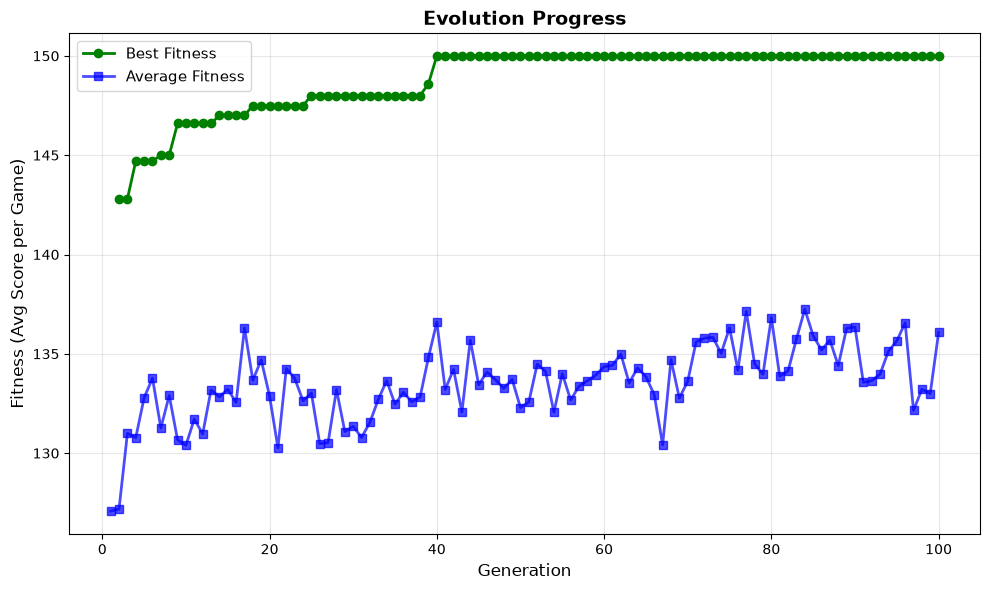


🎉 Your evolved agent's final genes:
   [0.4716112226172166, 0.7683594925354631, 0.8923051131781774, 0.12344299350222587, 1.0, 0.5831062993110613]


In [24]:

# ============================================================================
# PART 4: RUN EVOLUTION! 
# ============================================================================

print("\n" + "="*70)
print("🚀 TIME TO EVOLVE YOUR AGENT!")
print("="*70)

# TODO: Experiment with these parameters to find the best agent!
my_evolved_agent = evolve(
    generations=100,       # Try: 50, 100, 250
    pop_size=30,         # Try: 15, 20, 30
    opponents=opponent_pool,
    mutation_rate=0.1,  # Try: 0.1, 0.15, 0.2
    elitism=2            # Keep top 2 agents each generation
)

print(f"\n🎉 Your evolved agent's final genes:")
print(f"   {my_evolved_agent.genes}")



In [33]:

# ============================================================================
# PART 5: TEST YOUR AGENT
# ============================================================================

print("\n" + "="*70)
print("⚔️  TESTING YOUR AGENT AGAINST HAND-CODED OPPONENTS")
print("="*70 + "\n")

wins = 0
losses = 0
ties = 0

for opponent in opponent_pool:
    game = Game(my_evolved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    
    if my_score > opp_score:
        result = "✅ WON"
        wins += 1
    elif my_score < opp_score:
        result = "❌ LOST"
        losses += 1
    else:
        result = "🤝 TIED"
        ties += 1
    
    print(f"vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\n📊 Record: {wins} wins, {losses} losses, {ties} ties")
win_rate = wins / len(opponent_pool) * 100
print(f"🎯 Win Rate: {win_rate:.1f}%")




⚔️  TESTING YOUR AGENT AGAINST HAND-CODED OPPONENTS

vs Adaptive                 : 255 - 180  ✅ WON
vs Hard Majority            : 338 - 238  ✅ WON
vs Random (0.9)             : 329 - 239  ✅ WON
vs Random (0.3)             : 198 -  98  ✅ WON
vs Pavlov                   : 272 -  97  ✅ WON
vs Random (0.5)             : 229 - 224  ✅ WON
vs Always Invest            : 346 - 231  ✅ WON
vs Tit-for-Tat              : 233 - 228  ✅ WON
vs Tit-for-Two-Tats         : 327 - 252  ✅ WON
vs Prober                   : 114 - 104  ✅ WON

📊 Record: 10 wins, 0 losses, 0 ties
🎯 Win Rate: 100.0%


# Unit 5 Part 2: Benchmark Analysis

**After running your initial evolution and benchmark tests, answer these questions.**

---

## Performance Summary

| Opponent         | Result               | Your Score | Opp Score |
| ---------------- | -------------------- | ---------: | --------: |
| Adaptive         | W                    |        255 |       180 |
| Hard Majority    | W                    |        338 |       238 |
| Random (0.9)     | W                    |        329 |       239 |
| Random (0.3)     | W                    |        198 |        98 |
| Pavlov           | W                    |        272 |        97 |
| Random (0.5)     | W                    |        229 |       224 |
| Always Invest    | W                    |        346 |       231 |
| Tit-for-Tat      | W                    |        233 |       228 |
| Tit-for-Two-Tats | W                    |        327 |       252 |
| Prober           | W                    |        114 |       104 |
| **Total**        | **10 W / 0 L / 0 T** |  **2,641** | **1,891** |


---

## Analysis Questions

1. What was your agent's worst loss (greatest point differential) and why?

My agent did not have a loss in the benchmark tests. The closest matchup was against Random (0.5), where my agent won 229–224. This tells me that a 50/50 random opponent was difficult because its behavior was unpredictable and gave my agent fewer patterns to respond to.

2. What pattern do you see in wins vs. losses?

My agent performed well against every opponent and finished with a 10–0–0 record. The largest advantages came against Hard Majority, Random (0.9), Always Invest, and Tit-for-Two-Tats. These opponents have predictable behavior, which allows the evolved strategy to take advantage. The closest matches were Random (0.5), Tit-for-Tat, and Prober because their behavior is less predictable or can change in response to my agent.

3. What would make an agent more competitive?

Even though my agent won every benchmark matchup, it could still be improved by becoming more responsive to changes in opponent behavior. A stronger agent could recognize cooperation, defection, and intentional probing separately instead of treating every opponent action the same. It could also adjust its strategy based on both recent behavior and longer-term patterns.

---

**Next:** Proceed to Part 3 to implement your improvements!


In [ ]:

# ============================================================================
# PART 6: IMPROVE YOUR AGENT'S ACTION TAKING STRATEGY
# ============================================================================

class ImprovedEvolvableAgent(Agent):
    """
    S(herlock)anta Holmes agent.

    The agent evaluates whether an opponent is naughty or nice,
    rewards nice behavior, forgives isolated naughty behavior,
    and responds to repeated naughtiness.
    """

    def __init__(self, genes=None, name="S(herlock)anta Holmes"):
        if genes is None:
            genes = [random.random() for _ in range(6)]

        self.genes = genes

        super().__init__(
            name,
            f"Genes: [{', '.join([f'{gene:.2f}' for gene in genes])}]"
        )

    def choose_action(self) -> bool:

        opening_niceness = self.genes[0] # how nice Santa is at the beginning
        present_reward = self.genes[1] # how likely Santa is to reward nice behavior
        coal_retaliation = self.genes[2] # how likely Santa is to give coal for naughty behavior
        forgiveness = self.genes[3] # how willing Santa is to forgive naughtiness
        memory_length_gene = self.genes[4] # how much opponent history Santa remembers
        naughty_threshold_gene = self.genes[5] # how suspicious Santa is before deciding someone is naughty

        if self.round_num < 3:
            return random.random() < opening_niceness

        memory_length = max(
            1,
            int(memory_length_gene * 10) + 1
        )

        recent_history = self.history[-memory_length:]
        recent_niceness = sum(recent_history) / len(recent_history)

        long_length = max(10, memory_length * 2)

        if len(self.history) < long_length:
            long_history = self.history
        else:
            long_history = self.history[-long_length:]

        long_term_niceness = sum(long_history) / len(long_history)

        niceness_score = (
            recent_niceness * 0.7
            + long_term_niceness * 0.3
        )

        naughty_threshold = (
            0.30 + naughty_threshold_gene * 0.50
        )

        behavior_change = abs(
            recent_niceness - long_term_niceness
        )

        isolated_naughtiness = False

        if self.history[-1] == UNDERCUT:
            if (
                long_term_niceness >= naughty_threshold
                and recent_niceness >= 0.50
            ):
                isolated_naughtiness = True

        repeated_naughtiness = False

        if len(recent_history) >= 3:
            if recent_niceness < 0.34:
                repeated_naughtiness = True

        if behavior_change > 0.30:

            if self.history[-1] == UNDERCUT:

                if random.random() < coal_retaliation:
                    return UNDERCUT

                if random.random() < forgiveness:
                    return INVEST

                return UNDERCUT

            if random.random() < present_reward:
                return INVEST

            return UNDERCUT

        if isolated_naughtiness:

            if random.random() < forgiveness:
                return INVEST

            if random.random() < coal_retaliation:
                return UNDERCUT

            return INVEST

        if repeated_naughtiness:

            if random.random() < coal_retaliation:
                return UNDERCUT

            if random.random() < forgiveness:
                return INVEST

            return UNDERCUT

        if niceness_score >= naughty_threshold:

            if random.random() < present_reward:
                return INVEST

            return UNDERCUT

        if random.random() < coal_retaliation:
            return UNDERCUT

        if random.random() < forgiveness:
            return INVEST

        return UNDERCUT

    def save_to_file(self, filename):
        data = {
            'name': self.name,
            'genes': self.genes,
            'description': self.description
        }

        with open(filename, 'w') as f:
            json.dump(data, f, indent=2)

        print(f"Agent saved to {filename}")


🔧 EVOLVING YOUR IMPROVED AGENT!

🧬 EVOLUTION STARTING (Improved Agent)
Population: 30 | Generations: 100 | Mutation: 0.1
Opponents: 10 | Elitism: 2

Gen   1/100: Best=139.80 | Avg=126.98 | Genes=['0.43', '0.50', '0.36', '0.95', '0.31', '0.62']
Gen   2/100: Best=140.20 | Avg=133.15 | Genes=['0.27', '0.50', '0.36', '0.95', '0.31', '0.62']
Gen   3/100: Best=145.60 | Avg=132.60 | Genes=['0.43', '0.56', '0.36', '1.00', '0.09', '0.29']
Gen   4/100: Best=145.60 | Avg=132.72 | Genes=['0.27', '0.50', '0.36', '0.85', '0.10', '0.05']
Gen   5/100: Best=145.60 | Avg=132.68 | Genes=['0.43', '0.50', '0.36', '0.95', '0.31', '0.62']
Gen   6/100: Best=145.60 | Avg=135.51 | Genes=['0.58', '0.20', '0.36', '1.00', '0.54', '0.29']
Gen   7/100: Best=145.60 | Avg=133.91 | Genes=['0.43', '0.56', '0.42', '0.95', '0.31', '0.62']
Gen   8/100: Best=145.60 | Avg=133.79 | Genes=['0.48', '0.56', '0.42', '1.00', '0.09', '0.05']
Gen   9/100: Best=146.00 | Avg=133.24 | Genes=['0.48', '0.56', '0.42', '1.00', '0.09', '0.

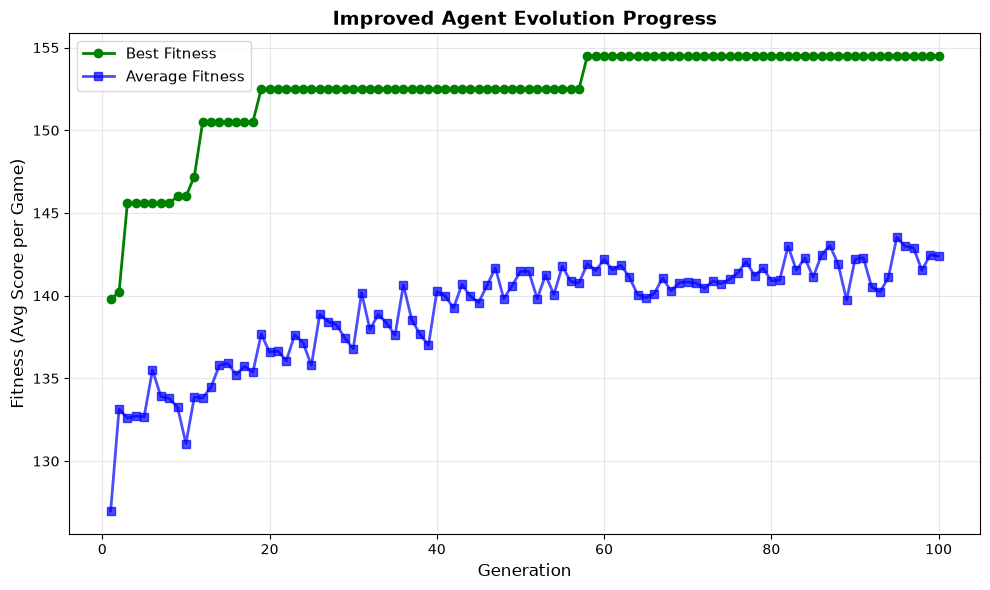


🎉 Your improved agent's final genes:
   [0.02449889017642974, 0.018033966708632505, 0.14866494128511734, 1.0, 0.38492083610472205, 0.4696607392073748]


In [52]:
# ============================================================================
# PART 7: EVOLVE YOUR IMPROVED AGENT
# ============================================================================


print("\n" + "="*70)
print("🔧 EVOLVING YOUR IMPROVED AGENT!")
print("="*70)


def evolve_improved(generations=25, pop_size=20, opponents=None, mutation_rate=0.15, elitism=2):
    """
    Evolve using the ImprovedEvolvableAgent class
    (Same as evolve() but uses ImprovedEvolvableAgent instead of EvolvableAgent)
    """
    if opponents is None:
        opponents = opponent_pool
    
    print(f"\n🧬 EVOLUTION STARTING (Improved Agent)")
    print(f"{'='*70}")
    print(f"Population: {pop_size} | Generations: {generations} | Mutation: {mutation_rate}")
    print(f"Opponents: {len(opponents)} | Elitism: {elitism}")
    print(f"{'='*70}\n")
    
    best_fitness_history = []
    avg_fitness_history = []
    
    # Initialize population with ImprovedEvolvableAgent
    population = [ImprovedEvolvableAgent(name=f"Agent_{i}") for i in range(pop_size)]
    
    best_overall_agent = None
    best_overall_fitness = -float('inf')
    
    for gen in range(generations):
        # Evaluate fitness
        fitnesses = []
        for agent in population:
            fitness = evaluate_fitness(agent, opponents, num_rounds=50)
            fitnesses.append(fitness)
        
        # Track best
        best_fitness = max(fitnesses)
        avg_fitness = sum(fitnesses) / len(fitnesses)
        
        # Update best overall
        best_idx = fitnesses.index(best_fitness)
        if best_fitness > best_overall_fitness:
            best_overall_fitness = best_fitness
            best_overall_agent = ImprovedEvolvableAgent(genes=population[best_idx].genes.copy())
        
        best_fitness_history.append(best_overall_fitness)
        avg_fitness_history.append(avg_fitness)
        
        print(f"Gen {gen+1:3d}/{generations}: "
              f"Best={best_overall_fitness:6.2f} | Avg={avg_fitness:6.2f} | "
              f"Genes={[f'{g:.2f}' for g in population[best_idx].genes]}")
        
        # Create next generation
        if gen < generations - 1:
            sorted_indices = sorted(range(len(fitnesses)), 
                                  key=lambda i: fitnesses[i], 
                                  reverse=True)
            
            # Elitism
            next_population = []
            for i in range(elitism):
                elite_genes = population[sorted_indices[i]].genes.copy()
                next_population.append(ImprovedEvolvableAgent(genes=elite_genes))
            
            # Selection
            selected = tournament_selection(population, fitnesses)
            
            # Crossover and mutation
            while len(next_population) < pop_size:
                parent1, parent2 = random.sample(selected, 2)
                child = crossover_and_mutate(parent1, parent2, mutation_rate)
                # Convert to ImprovedEvolvableAgent
                next_population.append(ImprovedEvolvableAgent(genes=child.genes))
            
            population = next_population
    
    print(f"\n{'='*70}")
    print(f"✅ EVOLUTION COMPLETE!")
    print(f"🏆 Best fitness achieved: {best_overall_fitness:.2f}")
    print(f"{'='*70}\n")
    
    # Plot
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, generations+1), best_fitness_history, 
             label='Best Fitness', linewidth=2, color='green', marker='o')
    plt.plot(range(1, generations+1), avg_fitness_history, 
             label='Average Fitness', linewidth=2, color='blue', marker='s', alpha=0.7)
    plt.xlabel('Generation', fontsize=12)
    plt.ylabel('Fitness (Avg Score per Game)', fontsize=12)
    plt.title('Improved Agent Evolution Progress', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return best_overall_agent


# TODO: Experiment with these parameters to find the best improved agent!
my_improved_agent = evolve_improved(
    generations=100,      # Try: 20, 30, 50
    pop_size=30,         # Try: 15, 20, 30
    opponents=opponent_pool,
    mutation_rate=0.1,   # Try: 0.1, 0.15, 0.2
    elitism=2            # Keep top 2 agents each generation
)

print(f"\n🎉 Your improved agent's final genes:")
print(f"   {my_improved_agent.genes}")

In [42]:

# ============================================================================
# PART 8.1: Compare: Original vs Improved
# ============================================================================

print("\n" + "="*70)
print("📊 COMPARISON: Original vs Improved Agent")
print("="*70 + "\n")

print("ORIGINAL AGENT:")
wins_orig = 0
for opponent in opponent_pool:
    game = Game(my_evolved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    if my_score > opp_score:
        wins_orig += 1
        result = "✅ WON"
    elif my_score < opp_score:
        result = "❌ LOST"
    else:
        result = "🤝 TIED"
    print(f"vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\nOriginal Win Rate: {wins_orig / len(opponent_pool) * 100:.1f}%")

print("\n" + "-"*70 + "\n")

print("IMPROVED AGENT:")
wins_improved = 0
for opponent in opponent_pool:
    game = Game(my_improved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    if my_score > opp_score:
        wins_improved += 1
        result = "✅ WON"
    elif my_score < opp_score:
        result = "❌ LOST"
    else:
        result = "🤝 TIED"
    print(f"vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\nImproved Win Rate: {wins_improved / len(opponent_pool) * 100:.1f}%")

print("\n" + "="*70)
print(f"📈 IMPROVEMENT: +{wins_improved - wins_orig} wins")
print("="*70)


# ============================================================================
# GENERALIZATION TEST: Full Opponent Pool
# ============================================================================

print("\n" + "="*70)
print("🌍 GENERALIZATION TEST: Against ALL Possible Opponents")
print("="*70 + "\n")

print("Testing improved agent against the FULL opponent library:")
print("(including agents it was NOT trained on)\n")

wins_full = 0
losses_full = 0
ties_full = 0

for opponent in full_opponent_pool:
    game = Game(my_improved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    
    if my_score > opp_score:
        result = "✅ WON"
        wins_full += 1
    elif my_score < opp_score:
        result = "❌ LOST"
        losses_full += 1
    else:
        result = "🤝 TIED"
        ties_full += 1
    
    # Mark if this was a training opponent
    trained_on = "📚" if any(opponent.name == o.name for o in opponent_pool) else "🆕"
    print(f"{trained_on} vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\n📊 Results against ALL {len(full_opponent_pool)} opponents:")
print(f"   Wins: {wins_full} | Losses: {losses_full} | Ties: {ties_full}")
print(f"   Win Rate: {wins_full / len(full_opponent_pool) * 100:.1f}%")
print(f"\n💡 Legend: 📚 = Trained on this opponent | 🆕 = Never seen before")
print("="*70)


📊 COMPARISON: Original vs Improved Agent

ORIGINAL AGENT:
vs Adaptive                 : 315 - 255  ✅ WON
vs Hard Majority            : 103 - 103  🤝 TIED
vs Random (0.9)             : 303 - 258  ✅ WON
vs Random (0.3)             : 224 - 119  ✅ WON
vs Pavlov                   : 272 - 102  ✅ WON
vs Random (0.5)             : 237 - 212  ✅ WON
vs Always Invest            : 352 - 222  ✅ WON
vs Tit-for-Tat              : 189 - 184  ✅ WON
vs Tit-for-Two-Tats         : 329 - 239  ✅ WON
vs Prober                   : 100 - 120  ❌ LOST

Original Win Rate: 80.0%

----------------------------------------------------------------------

IMPROVED AGENT:
vs Adaptive                 : 273 - 223  ✅ WON
vs Hard Majority            : 122 - 117  ✅ WON
vs Random (0.9)             : 345 - 205  ✅ WON
vs Random (0.3)             : 212 -  82  ✅ WON
vs Pavlov                   : 278 -  88  ✅ WON
vs Random (0.5)             : 257 - 102  ✅ WON
vs Always Invest            : 396 - 156  ✅ WON
vs Tit-for-Tat           

In [47]:

# ============================================================================
# PART 8.2: Compete in your final tournament
# ============================================================================

print("\n" + "="*70)
print("🏆 FULL TOURNAMENT COMPARISON")
print("="*70 + "\n")

# Create tournament with original agent
print("Running tournament with ORIGINAL agent...")
original_tournament_agents = full_opponent_pool + [my_evolved_agent]
original_tournament = Tournament(original_tournament_agents, rounds_per_match=100, num_tournaments=1)
original_tournament.run_tournament()

# Create tournament with improved agent
print("\n" + "-"*70)
print("\nRunning tournament with IMPROVED agent...")
improved_tournament_agents = full_opponent_pool + [my_improved_agent]
improved_tournament = Tournament(improved_tournament_agents, rounds_per_match=100, num_tournaments=1)
improved_tournament.run_tournament()

# Compare rankings
print("\n" + "="*70)
print("📊 TOURNAMENT RESULTS COMPARISON")
print("="*70 + "\n")

original_rankings = original_tournament.get_rankings()
improved_rankings = improved_tournament.get_rankings()

# Find where each agent placed
original_rank = None
improved_rank = None
original_score = None
improved_score = None

for rank, (name, score) in enumerate(original_rankings, 1):
    if name == my_evolved_agent.name:
        original_rank = rank
        original_score = score

for rank, (name, score) in enumerate(improved_rankings, 1):
    if name == my_improved_agent.name:
        improved_rank = rank
        improved_score = score

print(f"ORIGINAL AGENT:")
print(f"  Rank: {original_rank} / {len(original_rankings)}")
print(f"  Total Score: {original_score:,}")
print()
print(f"IMPROVED AGENT:")
print(f"  Rank: {improved_rank} / {len(improved_rankings)}")
print(f"  Total Score: {improved_score:,}")
print()
print(f"IMPROVEMENT:")
print(f"  Rank Change: {original_rank - improved_rank} positions {'⬆️' if improved_rank < original_rank else '⬇️' if improved_rank > original_rank else '➡️'}")
print(f"  Score Change: +{improved_score - original_score:,} points ({(improved_score - original_score)/original_score*100:.1f}%)")
print("="*70)

# Show full leaderboard
print("\n🏆 IMPROVED AGENT TOURNAMENT LEADERBOARD:")
print("=" * 50)
for rank, (name, score) in enumerate(improved_rankings, 1):
    emoji = "🥇" if rank == 1 else "🥈" if rank == 2 else "🥉" if rank == 3 else "  "
    marker = " ⭐ YOUR AGENT" if name == my_improved_agent.name else ""
    print(f"{emoji} {rank:2d}. {name:25s}: {score:,} points{marker}")


🏆 FULL TOURNAMENT COMPARISON

Running tournament with ORIGINAL agent...
Running 1 tournament(s) with 19 agents...
Match 1/342: Always Invest vs Tit-for-Tat
Match 2/342: Always Invest vs Grim Trigger
Match 3/342: Always Invest vs Pavlov
Match 4/342: Always Invest vs Tit-for-Two-Tats
Match 5/342: Always Invest vs Generous Tit-for-Tat
Match 6/342: Always Invest vs Adaptive
Match 7/342: Always Invest vs Always Undercut
Match 8/342: Always Invest vs Suspicious Tit-for-Tat
Match 9/342: Always Invest vs Gradual
Match 10/342: Always Invest vs Prober
Match 11/342: Always Invest vs Hard Majority
Match 12/342: Always Invest vs Soft Majority
Match 13/342: Always Invest vs Random (0.9)
Match 14/342: Always Invest vs Random (0.7)
Match 15/342: Always Invest vs Random (0.5)
Match 16/342: Always Invest vs Random (0.3)
Match 17/342: Always Invest vs Random (0.1)
Match 18/342: Always Invest vs Evolved Agent
Match 19/342: Tit-for-Tat vs Always Invest
Match 20/342: Tit-for-Tat vs Grim Trigger
Match 21/34

In [54]:
# ============================================================================
# PART 9: Export Complete Agent as Python Module
# ============================================================================

import inspect
from datetime import datetime

def export_complete_agent(agent, student_name, generations=100, final_fitness=None):
    """
    Export agent as a complete, standalone Python module.
    This preserves BOTH genes AND decision logic so your strategy maintains
    its competitive edge in the tournament!
    
    Args:
        agent: Your evolved ImprovedEvolvableAgent
        student_name: Your name (will be used in class name, e.g., "JohnSmith")
        generations: Number of generations you evolved for
        final_fitness: Your agent's final fitness score (optional)
    
    Returns:
        filename of the exported Python file
    """
    
    # Clean up student name for valid Python class name (remove spaces, special chars)
    clean_name = ''.join(c for c in student_name if c.isalnum())
    
    # Get the actual decision logic code
    decision_code = inspect.getsource(agent.choose_action)
    
    # The source code already has proper indentation from the class,
    # so we don't need to add extra indentation
    
    # Get training opponent names if available
    try:
        opponent_names = [opp.name for opp in opponent_pool]
        opponent_info = f"Trained against: {', '.join(opponent_names[:5])}{'...' if len(opponent_names) > 5 else ''}"
    except:
        opponent_info = "Training opponents: [info not available]"
    
    # Build the complete Python module
    code = f'''#!/usr/bin/env python
"""
Tournament Agent: {agent.name}
Student: {student_name}
Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

Evolution Details:
- Generations: {generations}
- Final Fitness: {final_fitness if final_fitness else 'N/A'}
- {opponent_info}

Strategy: {agent.description}
"""

from agents import Agent, INVEST, UNDERCUT
import random


class {clean_name}Agent(Agent):
    """
    {agent.name}
    
    {agent.description}
    
    Evolved Genes: {agent.genes}
    """
    
    def __init__(self):
        # These genes were evolved through {generations} generations
        self.genes = {agent.genes}
        
        # Required for tournament compatibility
        self.student_name = "{student_name}"
        
        super().__init__(
            name="{agent.name}",
            description="{agent.description}"
        )
    
{decision_code}


# Convenience function for tournament loading
def get_agent():
    """Return an instance of this agent for tournament use"""
    return {clean_name}Agent()


if __name__ == "__main__":
    # Test that the agent can be instantiated
    agent = get_agent()
    print(f"✅ Agent loaded successfully: {{agent.name}}")
    print(f"   Genes: {{agent.genes}}")
    print(f"   Description: {{agent.description}}")
'''
    
    # Save to file
    filename = f"{clean_name.lower()}_tournament_agent.py"
    with open(filename, 'w', encoding='utf-8') as f:
        f.write(code)
    
    print("="*70)
    print("✅ COMPLETE TOURNAMENT AGENT EXPORTED!")
    print("="*70)
    print(f"📄 File: {filename}")
    print(f"🏷️  Class: {clean_name}Agent")
    print(f"🧬 Genes: {agent.genes}")
    print()
    print("📦 What's included:")
    print("   ✓ Your evolved gene values")
    print("   ✓ Your complete decision logic (choose_action method)")
    print("   ✓ All metadata and documentation")
    print()
    print("🎯 Next Steps:")
    print(f"   1. Download '{filename}' from Jupyter")
    print("   2. Submit this .py file for the Unit 6 tournament")
    print("   3. Your strategy will compete exactly as it evolved!")
    print()
    print("🧪 Test your export:")
    print(f"   from {filename[:-3]} import get_agent")
    print("   my_agent = get_agent()")
    print("="*70)
    
    return filename


# ============================================================================
# RUN THIS: Export your improved agent
# ============================================================================

print("\n" + "="*70)
print("💾 EXPORTING YOUR TOURNAMENT AGENT")
print("="*70 + "\n")

# TODO: Customize these fields with your information
STUDENT_NAME = "Hutton Edney"  # <-- CHANGE THIS! (e.g., "JohnSmith" or "Alex_Chen")

# TODO: Give your agent a creative name and description
my_improved_agent.name = "S(herlock)anta Holmes"  # <-- CHANGE THIS! (e.g., "Vengeful Cooperator", "Strategic Punisher")
my_improved_agent.description = "Santa starts cautiously, watches what you do, forgives almost everything, and only gives coal when the evidence of naughtiness becomes strong."

print(f"Agent Name: {my_improved_agent.name}")
print(f"Description: {my_improved_agent.description}")
print(f"Genes: {[f'{g:.2f}' for g in my_improved_agent.genes]}\n")

# Export with all the context
exported_file = export_complete_agent(
    agent=my_improved_agent,
    student_name=STUDENT_NAME,
    generations=100,  # Update if you used different value
    final_fitness=154.50  # Optionally add your best fitness score (e.g., 85.2)
)

print(f"\n✨ Your agent is ready for tournament competition!")
print(f"   Unlike JSON exports, this preserves your evolved strategy.\n")



💾 EXPORTING YOUR TOURNAMENT AGENT

Agent Name: S(herlock)anta Holmes
Description: Santa starts cautiously, watches what you do, forgives almost everything, and only gives coal when the evidence of naughtiness becomes strong.
Genes: ['0.02', '0.02', '0.15', '1.00', '0.38', '0.47']

✅ COMPLETE TOURNAMENT AGENT EXPORTED!
📄 File: huttonedney_tournament_agent.py
🏷️  Class: HuttonEdneyAgent
🧬 Genes: [0.02449889017642974, 0.018033966708632505, 0.14866494128511734, 1.0, 0.38492083610472205, 0.4696607392073748]

📦 What's included:
   ✓ Your evolved gene values
   ✓ Your complete decision logic (choose_action method)
   ✓ All metadata and documentation

🎯 Next Steps:
   1. Download 'huttonedney_tournament_agent.py' from Jupyter
   2. Submit this .py file for the Unit 6 tournament
   3. Your strategy will compete exactly as it evolved!

🧪 Test your export:
   from huttonedney_tournament_agent import get_agent
   my_agent = get_agent()

✨ Your agent is ready for tournament competition!
   Unlike 

## Post-Evolution Reflection Questions

### 1. Generalization Analysis
- Compare your agent's performance on training opponents (📚) vs. unseen opponents (🆕)
- Did your agent generalize well or overfit to the training set?
- What does this suggest about evolving against a random sample vs. fixed opponents?

My agent performed well against the training opponents. I would compare this to the unseen opponents to see if the results stayed similar. If the scores were close, this would show that my agent generalized well instead of only learning how to beat the training opponents.

Evolving against a random sample of opponents is helpful because the agent sees different strategies. This can make it more prepared for opponents it has not seen before.

### 2. Tournament Performance
- What was your agent's final tournament rank? _____ out of _____
- What was your agent's total score? _____
- Look at agents that ranked above and below you - what strategies do they use?

My agent's final tournament rank was 8th out of 20.

My agent's total score was 4,391 points.

The agents above my agent included Prober, Tit-for-Tat, Hard Majority, and several other strategies. My agent finished just below Prober with 4,451 points and just above Adaptive with 4,390 points. Most of the top ones were nice agents, which didn't fair well for my mostly forgive attitude. 

### 3. Strategy Analysis
Look at your evolved genes: [0.02, 0.02, 0.15, 1.00, 0.38, 0.47].

- In plain English, what strategy did your agent evolve?
- Does it cooperate with cooperators? Does it punish defectors?
- Why do you think evolution discovered this particular strategy?

My agent evolved a cautious and forgiving strategy. It starts with very little cooperation and watches the opponent's behavior before making decisions. It is very forgiving when an opponent undercuts, but it can still punish repeated naughty behavior.

I think evolution discovered this strategy because being too aggressive can hurt against different types of opponents. Being more cautious and forgiving allowed my agent to avoid losing too many points while still responding to repeated bad behavior.

### 4. Trade-offs
Every strategy has strengths and weaknesses.

- Which types of opponents does your agent beat?
- Which types beat your agent?
- If you could redesign your agent for Unit 6, what would you change?

One weakness of my agent is that it is very forgiving. An opponent that repeatedly undercuts could take advantage of this. My agent also does not cooperate very often, so it can miss opportunities to gain more points against cooperative opponents.

For Unit 6, I would make my agent better at recognizing repeated undercutting while still keeping some forgiveness for occasional defections.

### 5. The Environment Matters
- You evolved against a random sample of 10 opponents
- The tournament included all 19 opponents
- Unit 6 will include 30+ student agents with unpredictable strategies
- How might your agent perform in that different environment?

My agent was trained against a random sample of 10 opponents, but the tournament included 19 different opponents. It still finished 8th, which shows that the strategy worked against a larger group of opponents. 

My agent should still perform reasonably well because it watches opponent behavior instead of always using the same strategy. However, I would make it better at dealing with aggressive opponents so it is harder to take advantage of its forgiving strategy.
